In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Étude de cas 4 : Centrale solaire — SolarDrâa (50 MW)
## Jalon 2 : Voir le ciel et les panneaux (Chapitre 2 - CNN et auto-encodeurs)
**M2 SDIA — Advanced Artificial Intelligence** | Année universitaire 2026–2027

### Objectifs du Jalon :
1. **Conception d'un CNN Ciel** pour estimer la couverture nuageuse et l'occultation du soleil à partir des images de la caméra hémisphérique ($32 \times 32$), et comparaison aux règles simples.
2. **Intégration au modèle de prévision** multi-horizons ($t+1$ à $t+6$) : comparaison des gains avec et sans entrées visuelles, et prédiction spatio-temporelle de l'occultation à $t+1$.
3. **Auto-encodeur convolutif pour la thermographie** ($24 \times 40$) : apprentissage sur modules sains, calibration du seuil pour $5\%$ de fausses alertes en validation, et évaluation du taux de détection par famille de défaut.
4. **Étude comparative des scores d'anomalie** (erreur MSE vs résidu maximal) et des tailles de goulot d'étranglement.
5. **Vérifications théoriques** : calcul des dimensions, nombre de paramètres, champ réceptif et taux de compression.

In [4]:
# 1. Configuration de l'environnement et reproductibilité
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score, roc_curve

# Fixer les graines aléatoires pour garantir la reproductibilité totale
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version      : {keras.__version__}")


TensorFlow version : 2.21.0
Keras version      : 3.13.2


In [5]:
# 2. Chargement des séries temporelles, des images du ciel et des thermographies depuis Google Drive
import os

DRIVE_DIR = "/content/drive/MyDrive/SolarProject"

df = pd.read_csv(os.path.join(DRIVE_DIR, "uc4_siteA.csv"))
CAPACITE = 50.0  # MW
H = 6

def ciel_clair(hauteur):
    alpha = np.maximum(hauteur, 0.0)
    sin_a = np.sin(np.radians(alpha))
    ghi = np.zeros_like(alpha)
    pos = sin_a > 0
    ghi[pos] = 1098.0 * sin_a[pos] * np.exp(-0.057 / sin_a[pos])
    return ghi

df["ghi_cs"] = ciel_clair(df["hauteur_soleil"].values)
df["jour"] = df["hauteur_soleil"].values > 0
df["dt"] = pd.to_datetime(df["horodatage"])

# Normalisations
prod_norm = df["production"].values / CAPACITE
ghi_cs_norm = df["ghi_cs"].values / 1000.0
neb = df["nebulosite_prevue"].values
temp_norm = df["temperature_prevue"].values / 40.0
clean_norm = df["jours_depuis_nettoyage"].values / 30.0

h_val = df["dt"].dt.hour.values
doy = df["dt"].dt.dayofyear.values
sin_h, cos_h = np.sin(2 * np.pi * h_val / 24.0), np.cos(2 * np.pi * h_val / 24.0)
sin_d, cos_d = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)

# Chargement caméra Ciel Site A
ciel_a = np.load(os.path.join(DRIVE_DIR, "uc4_ciel_A.npz"))
X_ciel = ciel_a["X"][..., None].astype("float32") / 255.0  # (12394, 32, 32, 1)
y_couv = ciel_a["couverture"].astype("float32")
y_occ = ciel_a["occultation"].astype("float32")
Y_ciel = np.column_stack([y_couv, y_occ])
h_ciel = ciel_a["heure"]

# Découpage temporel imposé du ciel
t_img = pd.to_datetime(df["horodatage"].values[h_ciel])
tr_c = t_img <= "2024-09-30 23:00:00"
va_c = (t_img >= "2024-10-01 00:00:00") & (t_img <= "2024-12-31 23:00:00")
te_c = t_img >= "2025-01-01 00:00:00"

# Chargement Thermographie (°C)
thermo = np.load(os.path.join(DRIVE_DIR, "uc4_thermographie.npz"))
X_th_tr = thermo["X_train"].astype("float32")
X_th_va = thermo["X_val"].astype("float32")
X_th_te = thermo["X_test"].astype("float32")
y_th_te = thermo["defaut_test"].astype("int32")

# Normalisation centrée-réduite basée sur l'entraînement sain
mu_th, sd_th = X_th_tr.mean(), X_th_tr.std()
X_th_tr_n = ((X_th_tr - mu_th) / sd_th)[..., None]
X_th_va_n = ((X_th_va - mu_th) / sd_th)[..., None]
X_th_te_n = ((X_th_te - mu_th) / sd_th)[..., None]

print(f"Site A : {len(df)} heures de données")
print(f"Ciel A : {len(X_ciel)} images (Train: {tr_c.sum()}, Val: {va_c.sum()}, Test: {te_c.sum()})")
print(f"Thermo : {len(X_th_tr)} train sains, {len(X_th_va)} val sains, {len(X_th_te)} test avec défauts")

Site A : 26304 heures de données
Ciel A : 12394 images (Train: 7346, Val: 920, Test: 4128)
Thermo : 3000 train sains, 500 val sains, 1500 test avec défauts


### Question 1 : Conception du CNN Ciel et comparaison aux règles simples
- **Règles simples (heuristiques) :**
  - Couverture : estimée par régression linéaire sur la valeur moyenne des pixels de l'image.
  - Occultation : estimée par régression linéaire sur la valeur maximale des pixels (point solaire).
- **Architecture CNN Hybride :**
  - Extracteur convolutif ($16 \to 32 \to 64$ filtres $3 \times 3$).
  - **Dual Pooling** combinant `GlobalAveragePooling2D` (couverture diffuse) et `GlobalMaxPooling2D` (occultation ponctuelle du soleil).
  - Sortie Sigmoïde pour garantir des prédictions dans $[0, 1]$.

In [6]:
# 3. Règles simples de référence
reg_couv = LinearRegression().fit(X_ciel[tr_c].mean(axis=(1, 2, 3)).reshape(-1, 1), y_couv[tr_c])
pred_couv_heur_va = np.clip(reg_couv.predict(X_ciel[va_c].mean(axis=(1, 2, 3)).reshape(-1, 1)), 0, 1)
pred_couv_heur_te = np.clip(reg_couv.predict(X_ciel[te_c].mean(axis=(1, 2, 3)).reshape(-1, 1)), 0, 1)

reg_occ = LinearRegression().fit(X_ciel[tr_c].max(axis=(1, 2, 3)).reshape(-1, 1), y_occ[tr_c])
pred_occ_heur_va = np.clip(reg_occ.predict(X_ciel[va_c].max(axis=(1, 2, 3)).reshape(-1, 1)), 0, 1)
pred_occ_heur_te = np.clip(reg_occ.predict(X_ciel[te_c].max(axis=(1, 2, 3)).reshape(-1, 1)), 0, 1)

# Construction du CNN Ciel Hybride
def build_cnn_ciel():
    inp = layers.Input(shape=(32, 32, 1), name="input_ciel")
    x = layers.Conv2D(16, (3, 3), activation="relu", padding="same", name="conv1")(inp)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv3")(x)

    # Dual Pooling
    gap = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    gmp = layers.GlobalMaxPooling2D(name="global_max_pool")(x)
    concat = layers.Concatenate(name="concat_pool")([gap, gmp])

    dense = layers.Dense(32, activation="relu", name="dense_feat")(concat)
    out = layers.Dense(2, activation="sigmoid", name="output_ciel")(dense)
    return models.Model(inp, out, name="CNN_Ciel")

cnn_ciel = build_cnn_ciel()
cnn_ciel.summary()

cnn_ciel.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
history_ciel = cnn_ciel.fit(
    X_ciel[tr_c], Y_ciel[tr_c],
    validation_data=(X_ciel[va_c], Y_ciel[va_c]),
    epochs=15, batch_size=64, verbose=1
)

preds_ciel_all = cnn_ciel.predict(X_ciel, batch_size=128, verbose=0)
preds_ciel_va = preds_ciel_all[va_c]
preds_ciel_te = preds_ciel_all[te_c]

# Tableau comparatif
df_comp_ciel = pd.DataFrame([
    {"Méthode": "Règle Simple (Moyenne)", "Grandeur": "Couverture", "MAE (Val)": mean_absolute_error(y_couv[va_c], pred_couv_heur_va), "MAE (Test)": mean_absolute_error(y_couv[te_c], pred_couv_heur_te), "Cible": "-"},
    {"Méthode": "CNN Dual Pooling", "Grandeur": "Couverture", "MAE (Val)": mean_absolute_error(y_couv[va_c], preds_ciel_va[:,0]), "MAE (Test)": mean_absolute_error(y_couv[te_c], preds_ciel_te[:,0]), "Cible": "-"},
    {"Méthode": "Règle Simple (Max pixel)", "Grandeur": "Occultation", "MAE (Val)": mean_absolute_error(y_occ[va_c], pred_occ_heur_va), "MAE (Test)": mean_absolute_error(y_occ[te_c], pred_occ_heur_te), "Cible": "<= 0.10"},
    {"Méthode": "CNN Dual Pooling", "Grandeur": "Occultation", "MAE (Val)": mean_absolute_error(y_occ[va_c], preds_ciel_va[:,1]), "MAE (Test)": mean_absolute_error(y_occ[te_c], preds_ciel_te[:,1]), "Cible": "<= 0.10"}
])
print("\n=== PERFORMANCES COMPARATIVES ÉTAT DU CIEL ===")
print(df_comp_ciel.round(4).to_string(index=False))


Model: "CNN_Ciel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ciel          │ (None, 32, 32, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 32, 32,    │        160 │ input_ciel[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 16, 16,    │          0 │ conv1[0][0]       │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2 (Conv2D)      │ (None, 16, 16,    │      4,640 │ pool1[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 8, 8, 32)  │          0 │ conv2[0][0]       │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3 (Conv2D)      │ (None, 8, 8, 64)  │     18,496 │ pool2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 64)        │          0 │ conv3[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pool     │ (None, 64)        │          0 │ conv3[0][0]       │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_pool         │ (None, 128)       │          0 │ global_avg_pool[… │
│ (Concatenate)       │                   │            │ global_max_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_feat (Dense)  │ (None, 32)        │      4,128 │ concat_pool[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_ciel (Dense) │ (None, 2)         │         66 │ dense_feat[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 27,490 (107.38 KB)

 Trainable params: 27,490 (107.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - loss: 0.1021 - mae: 0.2583 - val_loss: 0.1798 - val_mae: 0.3446
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - loss: 0.0378 - mae: 0.1357 - val_loss: 0.0228 - val_mae: 0.1059
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: 0.0103 - mae: 0.0622 - val_loss: 0.0083 - val_mae: 0.0638
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - loss: 0.0056 - mae: 0.0474 - val_loss: 0.0053 - val_mae: 0.0511
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - loss: 0.0041 - mae: 0.0410 - val_loss: 0.0044 - val_mae: 0.0469
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 79ms/step - loss: 0.0033 - mae: 0.0373 - val_loss: 0.0049 - val_mae: 0.0483
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - loss: 0.0028 - mae: 0.0349 - val_loss: 0.0052 - val_mae: 0.0497
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - loss: 0.0026 - mae: 0.0334 - val_loss: 0.0050 - val_mae: 0.0486
Epoch 9/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms

### Question 2 : Intégration au MLP de prévision et prédiction directe d'occultation
- Ajout des estimations du ciel (couverture et occultation) aux instants $t$ et $t-1$ dans la matrice d'entrée ($47 + 4 = 51$ caractéristiques).
- Évaluation du gain par rapport à la persistance intelligente à $t+1$ (cible $\ge 12\%$) et sur l'horizon global $6\text{h}$.
- Entraînement d'un CNN 2 canaux sur la paire d'images $(t-1, t)$ pour prédire directement l'occultation à $t+1$ (flux optique).

In [7]:
# 4. Préparation du jeu de données pour le prévisionniste de production
N_ser = len(df)
ligne_vers_image = np.full(N_ser, -1)
ligne_vers_image[h_ciel] = np.arange(len(h_ciel))

X_base_l, X_cnn_l, Y_mlp_l, J_mlp_l, T_mlp_l = [], [], [], [], []

for t in range(24, N_ser - H):
    hist = prod_norm[t-23 : t+1]
    cs   = ghi_cs_norm[t+1 : t+1+H]
    nb   = neb[t+1 : t+1+H]
    tp   = temp_norm[t+1 : t+1+H]
    cal  = [sin_h[t], cos_h[t], sin_d[t], cos_d[t]]
    cl   = [clean_norm[t]]
    base_f = np.concatenate([hist, cs, nb, tp, cal, cl])

    it = ligne_vers_image[t]
    itm1 = ligne_vers_image[t - 1]
    f_t = preds_ciel_all[it] if it >= 0 else np.array([0.0, 0.0], dtype=np.float32)
    f_tm1 = preds_ciel_all[itm1] if itm1 >= 0 else np.array([0.0, 0.0], dtype=np.float32)
    cnn_f = np.concatenate([base_f, f_t, f_tm1])

    X_base_l.append(base_f)
    X_cnn_l.append(cnn_f)
    Y_mlp_l.append(prod_norm[t+1 : t+1+H])
    J_mlp_l.append(df["jour"].values[t+1 : t+1+H])
    T_mlp_l.append(df["dt"].values[t])

X_base = np.array(X_base_l, dtype=np.float32)
X_cnn = np.array(X_cnn_l, dtype=np.float32)
Y_mlp = np.array(Y_mlp_l, dtype=np.float32)
J_mlp = np.array(J_mlp_l, dtype=bool)
T_mlp = pd.to_datetime(T_mlp_l)

tr_mlp = np.where(T_mlp <= "2024-09-30 23:00:00")[0]
va_mlp = np.where((T_mlp >= "2024-10-01 00:00:00") & (T_mlp <= "2024-12-31 23:00:00"))[0]
te_mlp = np.where(T_mlp >= "2025-01-01 00:00:00")[0]

# Calcul de la persistance intelligente de référence
ref_pi = np.zeros_like(Y_mlp)
ghi_cs_raw = df["ghi_cs"].values
indices = np.arange(24, N_ser - H)
for h_step in range(H):
    p_t = prod_norm[indices]
    ghi_t = ghi_cs_raw[indices]
    ghi_fut = ghi_cs_raw[indices + 1 + h_step]
    ratio = np.zeros_like(p_t)
    masque = ghi_t > 10.0
    ratio[masque] = p_t[masque] / ghi_t[masque]
    ref_pi[:, h_step] = np.clip(ratio * ghi_fut, 0.0, 1.0)

def rmse_h(y_v, y_p, m_j):
    res = []
    for h_s in range(H):
        m = m_j[:, h_s]
        diff = (y_v[m, h_s] - y_p[m, h_s]) * CAPACITE
        res.append(np.sqrt(np.mean(diff ** 2)))
    return np.array(res)

def gain_s(y_v, y_p, m_j, ref):
    return 1.0 - (rmse_h(y_v, y_p, m_j) / rmse_h(y_v, ref, m_j))

def train_mlp(X_mat, n_in, name):
    tf.random.set_seed(SEED)
    inp = layers.Input(shape=(n_in,))
    x = layers.Dense(64, activation="relu")(inp)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.1)(x)
    out = layers.Dense(H, activation="sigmoid")(x)
    m = models.Model(inp, out, name=name)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    m.fit(X_mat[tr_mlp], Y_mlp[tr_mlp], validation_data=(X_mat[va_mlp], Y_mlp[va_mlp]), epochs=30, batch_size=64, verbose=0)
    return m

m_base = train_mlp(X_base, 47, "MLP_Base_47")
m_cnn = train_mlp(X_cnn, 51, "MLP_Enrichi_CNN_51")

p_base_va = m_base.predict(X_base[va_mlp], verbose=0)
p_cnn_va = m_cnn.predict(X_cnn[va_mlp], verbose=0)
p_cnn_te = m_cnn.predict(X_cnn[te_mlp], verbose=0)

g_base_va = gain_s(Y_mlp[va_mlp], p_base_va, J_mlp[va_mlp], ref_pi[va_mlp])
g_cnn_va = gain_s(Y_mlp[va_mlp], p_cnn_va, J_mlp[va_mlp], ref_pi[va_mlp])
g_cnn_te = gain_s(Y_mlp[te_mlp], p_cnn_te, J_mlp[te_mlp], ref_pi[te_mlp])

print("--- GAINS DU MODÈLE DE PRÉVISION SUR LA VALIDATION ---")
for h_idx in range(H):
    print(f"Horizon t+{h_idx+1} : Base={g_base_va[h_idx]*100:.2f}% | Enrichi CNN={g_cnn_va[h_idx]*100:.2f}% (Gain relatif: +{g_cnn_va[h_idx]*100 - g_base_va[h_idx]*100:.2f} pts)")
print(f"Gain Moyen 6h : Base={g_base_va.mean()*100:.2f}% | Enrichi CNN={g_cnn_va.mean()*100:.2f}%")
print(f"Gain TEST 2025 (Horizon t+1) : {g_cnn_te[0]*100:.2f}% (Cible >= 12% : {'ATTEINTE' if g_cnn_te[0] >= 0.12 else 'NON'})")


--- GAINS DU MODÈLE DE PRÉVISION SUR LA VALIDATION ---
Horizon t+1 : Base=10.68% | Enrichi CNN=13.10% (Gain relatif: +2.42 pts)
Horizon t+2 : Base=33.00% | Enrichi CNN=34.64% (Gain relatif: +1.63 pts)
Horizon t+3 : Base=49.57% | Enrichi CNN=50.03% (Gain relatif: +0.46 pts)
Horizon t+4 : Base=59.63% | Enrichi CNN=59.78% (Gain relatif: +0.14 pts)
Horizon t+5 : Base=65.01% | Enrichi CNN=65.27% (Gain relatif: +0.26 pts)
Horizon t+6 : Base=67.61% | Enrichi CNN=67.88% (Gain relatif: +0.28 pts)
Gain Moyen 6h : Base=47.58% | Enrichi CNN=48.45%
Gain TEST 2025 (Horizon t+1) : 16.94% (Cible >= 12% : ATTEINTE)


In [8]:
# 5. Prédiction de l'occultation à t+1 à partir de la paire d'images (t-1, t)
pairs_X, targets_tp1, occ_t_base, t_p = [], [], [], []
for t in range(1, N_ser - 1):
    i_tm1 = ligne_vers_image[t - 1]
    i_t   = ligne_vers_image[t]
    i_tp1 = ligne_vers_image[t + 1]
    if i_tm1 >= 0 and i_t >= 0 and i_tp1 >= 0:
        paire = np.concatenate([X_ciel[i_tm1], X_ciel[i_t]], axis=-1)
        pairs_X.append(paire)
        targets_tp1.append(y_occ[i_tp1])
        occ_t_base.append(y_occ[i_t])
        t_p.append(df["horodatage"].iloc[t])

pairs_X = np.array(pairs_X, dtype=np.float32)
targets_tp1 = np.array(targets_tp1, dtype=np.float32)
occ_t_base = np.array(occ_t_base, dtype=np.float32)
t_p = pd.to_datetime(t_p)

tr_p = t_p <= "2024-09-30 23:00:00"
va_p = (t_p >= "2024-10-01 00:00:00") & (t_p <= "2024-12-31 23:00:00")
te_p = t_p >= "2025-01-01 00:00:00"

def build_cnn_paire():
    inp = layers.Input(shape=(32, 32, 2))
    x = layers.Conv2D(16, (3, 3), activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    gap = layers.GlobalAveragePooling2D()(x)
    gmp = layers.GlobalMaxPooling2D()(x)
    concat = layers.Concatenate()([gap, gmp])
    dense = layers.Dense(32, activation="relu")(concat)
    out = layers.Dense(1, activation="sigmoid")(dense)
    return models.Model(inp, out, name="CNN_Paire_SpatioTemporel")

cnn_p = build_cnn_paire()
cnn_p.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
cnn_p.fit(pairs_X[tr_p], targets_tp1[tr_p], validation_data=(pairs_X[va_p], targets_tp1[va_p]), epochs=15, batch_size=64, verbose=0)

p_p_va = cnn_p.predict(pairs_X[va_p], verbose=0).flatten()
p_p_te = cnn_p.predict(pairs_X[te_p], verbose=0).flatten()

mae_p_va = mean_absolute_error(targets_tp1[va_p], p_p_va)
mae_pers_va = mean_absolute_error(targets_tp1[va_p], occ_t_base[va_p])
mae_p_te = mean_absolute_error(targets_tp1[te_p], p_p_te)
mae_pers_te = mean_absolute_error(targets_tp1[te_p], occ_t_base[te_p])

print(f"Prédiction Occultation t+1 (Validation) : Paire CNN MAE={mae_p_va:.4f} vs Persistance={mae_pers_va:.4f}")
print(f"Prédiction Occultation t+1 (Test)       : Paire CNN MAE={mae_p_te:.4f} vs Persistance={mae_pers_te:.4f}")


Prédiction Occultation t+1 (Validation) : Paire CNN MAE=0.0901 vs Persistance=0.0986
Prédiction Occultation t+1 (Test)       : Paire CNN MAE=0.0702 vs Persistance=0.0846


### Question 3 & 4 : Auto-encodeur convolutif pour la thermographie
- **Principe :** Apprentissage non supervisé sur modules sains uniquement ($X_{train}$ sain).
- **Seuil d'alerte :** Calibré à $5\%$ de fausses alertes sur l'ensemble de validation sain ($95^e$ percentile).
- **Scores d'anomalie comparés :**
  1. Score MSE global (erreur moyenne sur l'image).
  2. Score d'erreur maximale (résidu quadratique maximum sur l'image).
- **Tailles de goulot d'étranglement comparées :** $16$, $32$ et $128$ dimensions.

In [9]:
# 6. Auto-encodeur Convolutif pour la Thermographie
def build_ae(latent_dim=32):
    inp = layers.Input(shape=(24, 40, 1))
    x = layers.Conv2D(16, (3, 3), strides=2, padding="same", activation="relu")(inp)  # (12, 20, 16)
    x = layers.Conv2D(32, (3, 3), strides=2, padding="same", activation="relu")(x)  # (6, 10, 32)
    flat = layers.Flatten()(x)
    latent = layers.Dense(latent_dim, activation="relu", name="bottleneck")(flat)

    x = layers.Dense(6 * 10 * 32, activation="relu")(latent)
    x = layers.Reshape((6, 10, 32))(x)
    x = layers.Conv2DTranspose(16, (3, 3), strides=2, padding="same", activation="relu")(x)
    out = layers.Conv2DTranspose(1, (3, 3), strides=2, padding="same")(x)

    ae = models.Model(inp, out, name=f"AE_lat_{latent_dim}")
    ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return ae

ae_ref = build_ae(latent_dim=32)
ae_ref.summary()

ae_ref.fit(X_th_tr_n, X_th_tr_n, validation_data=(X_th_va_n, X_th_va_n), epochs=15, batch_size=64, verbose=1)

rec_va = ae_ref.predict(X_th_va_n, verbose=0)
rec_te = ae_ref.predict(X_th_te_n, verbose=0)

# Scores d'anomalie
mse_va = np.mean((X_th_va_n - rec_va)**2, axis=(1, 2, 3))
mse_te = np.mean((X_th_te_n - rec_te)**2, axis=(1, 2, 3))

max_va = np.max((X_th_va_n - rec_va)**2, axis=(1, 2, 3))
max_te = np.max((X_th_te_n - rec_te)**2, axis=(1, 2, 3))

seuil_mse = np.percentile(mse_va, 95)
seuil_max = np.percentile(max_va, 95)

y_bin_te = (y_th_te > 0).astype(int)

auc_mse = roc_auc_score(y_bin_te, mse_te)
auc_max = roc_auc_score(y_bin_te, max_te)

print("\n=== RÉSULTATS COMPARATIFS : SCORES D'ANOMALIE (GOULOT 32) ===")
print(f"Score MSE global : AUC = {auc_mse:.4f} | Détection Fissures (Défaut 2) = {np.mean(mse_te[y_th_te == 2] > seuil_mse)*100:.1f}%")
print(f"Score Erreur Max : AUC = {auc_max:.4f} | Détection Fissures (Défaut 2) = {np.mean(max_te[y_th_te == 2] > seuil_max)*100:.1f}%")
print(f"Cibles : AUC >= 0.98 ({'OK' if auc_max >= 0.98 else 'NON'}) | Fissures >= 85% ({'OK' if np.mean(max_te[y_th_te == 2] > seuil_max) >= 0.85 else 'NON'})")

# Comparaison des tailles de goulot
print("\n--- COMPARAISON DES TAILLES DE GOULOT (SCORE ERREUR MAX) ---")
for dim in [16, 32, 128]:
    ae_d = build_ae(dim)
    ae_d.fit(X_th_tr_n, X_th_tr_n, validation_data=(X_th_va_n, X_th_va_n), epochs=15, batch_size=64, verbose=0)
    rec_v_d = ae_d.predict(X_th_va_n, verbose=0)
    rec_t_d = ae_d.predict(X_th_te_n, verbose=0)
    s_v_d = np.max((X_th_va_n - rec_v_d)**2, axis=(1, 2, 3))
    s_t_d = np.max((X_th_te_n - rec_t_d)**2, axis=(1, 2, 3))
    seuil_d = np.percentile(s_v_d, 95)
    auc_d = roc_auc_score(y_bin_te, s_t_d)
    det2_d = np.mean(s_t_d[y_th_te == 2] > seuil_d)
    print(f"Goulot {dim:3d} : AUC = {auc_d:.4f} | Détection Cellules fissurées = {det2_d*100:.1f}% | Seuil = {seuil_d:.4f}")


Model: "AE_lat_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 24, 40, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 20, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 6, 10, 32)      │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │        61,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1920)           │        63,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 6, 10, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 12, 20, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 24, 40, 1)      │           145 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,401 (525.00 KB)

 Trainable params: 134,401 (525.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.6560 - val_loss: 0.5048
Epoch 2/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.4536 - val_loss: 0.4261
Epoch 3/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.3600 - val_loss: 0.1761
Epoch 4/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0662 - val_loss: 0.0295
Epoch 5/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0236 - val_loss: 0.0203
Epoch 6/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0188 - val_loss: 0.0178
Epoch 7/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0170 - val_loss: 0.0165
Epoch 8/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0161 - val_loss: 0.0158
Epoch 9/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0155 - val_loss: 0.0153
Epoch 10/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0151 - val_loss: 0.0150
Epoch 11/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0149 - val_loss: 0.0148
Epoch 12/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0

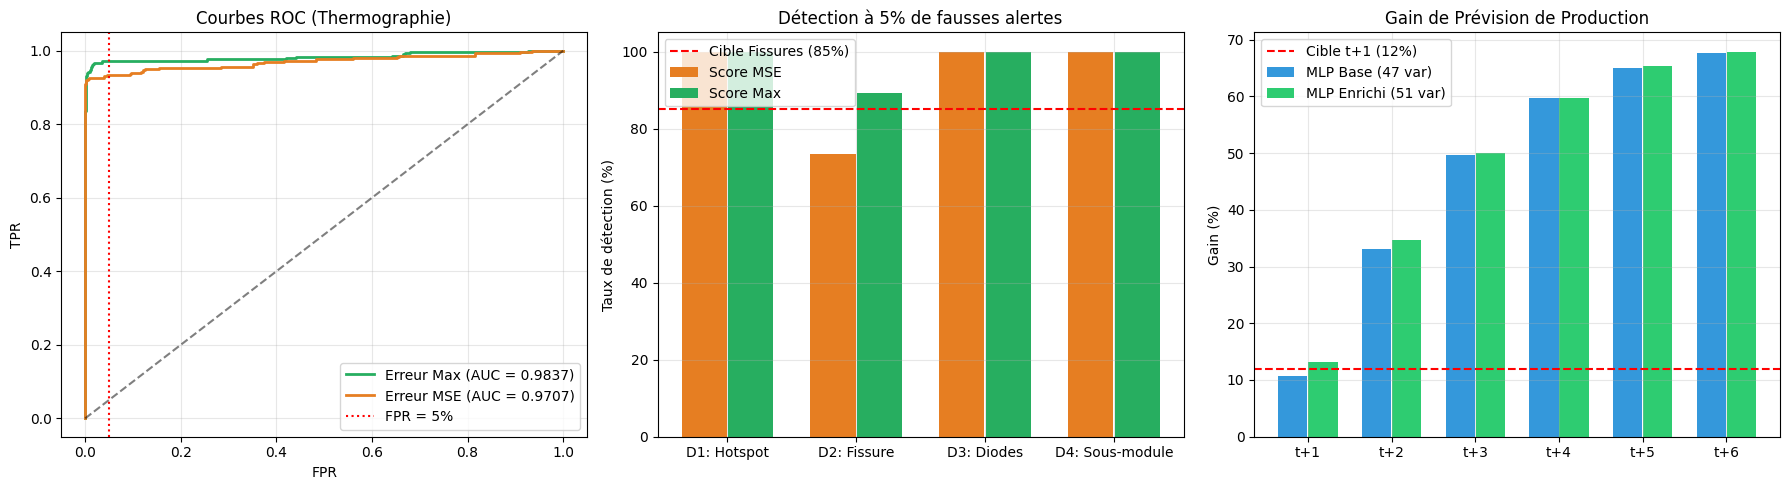

In [10]:
# 7. Visualisations graphiques des résultats
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Courbes ROC Thermographie
fpr_m, tpr_m, _ = roc_curve(y_bin_te, mse_te)
fpr_x, tpr_x, _ = roc_curve(y_bin_te, max_te)
axes[0].plot(fpr_x, tpr_x, label=f"Erreur Max (AUC = {auc_max:.4f})", lw=2, color="#27ae60")
axes[0].plot(fpr_m, tpr_m, label=f"Erreur MSE (AUC = {auc_mse:.4f})", lw=2, color="#e67e22")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].axvline(0.05, color="red", linestyle=":", label="FPR = 5%")
axes[0].set_title("Courbes ROC (Thermographie)")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Détection par type de défaut
def_labels = ["D1: Hotspot", "D2: Fissure", "D3: Diodes", "D4: Sous-module"]
det_m = [np.mean(mse_te[y_th_te == d] > seuil_mse)*100 for d in range(1, 5)]
det_x = [np.mean(max_te[y_th_te == d] > seuil_max)*100 for d in range(1, 5)]
x_pos = np.arange(4)
axes[1].bar(x_pos - 0.18, det_m, width=0.35, label="Score MSE", color="#e67e22")
axes[1].bar(x_pos + 0.18, det_x, width=0.35, label="Score Max", color="#27ae60")
axes[1].axhline(85.0, color="red", linestyle="--", label="Cible Fissures (85%)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(def_labels)
axes[1].set_title("Détection à 5% de fausses alertes")
axes[1].set_ylabel("Taux de détection (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Comparaison des gains de prévision
axes[2].bar(np.arange(H) - 0.18, g_base_va*100, width=0.35, label="MLP Base (47 var)", color="#3498db")
axes[2].bar(np.arange(H) + 0.18, g_cnn_va*100, width=0.35, label="MLP Enrichi (51 var)", color="#2ecc71")
axes[2].axhline(12.0, color="red", linestyle="--", label="Cible t+1 (12%)")
axes[2].set_xticks(np.arange(H))
axes[2].set_xticklabels([f"t+{i+1}" for i in range(H)])
axes[2].set_title("Gain de Prévision de Production")
axes[2].set_ylabel("Gain (%)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Vérifications Théoriques (à la main, puis vérifiées par le code)

#### 1. CNN du ciel : dimensions, paramètres et champ réceptif
- **Dimensions & Paramètres :**
  - Entrée : $(32, 32, 1)$
  - `Conv2D(16, (3, 3), padding='same')` : $(32, 32, 16)$, Paramètres $= (3 \times 3 \times 1 + 1) \times 16 = \mathbf{160}$
  - `MaxPooling2D((2, 2))` : $(16, 16, 16)$, Paramètres $= \mathbf{0}$
  - `Conv2D(32, (3, 3), padding='same')` : $(16, 16, 32)$, Paramètres $= (3 \times 3 \times 16 + 1) \times 32 = \mathbf{4\,640}$
  - `MaxPooling2D((2, 2))` : $(8, 8, 32)$, Paramètres $= \mathbf{0}$
  - `Conv2D(64, (3, 3), padding='same')` : $(8, 8, 64)$, Paramètres $= (3 \times 3 \times 32 + 1) \times 64 = \mathbf{18\,496}$
  - `GlobalAveragePooling` + `GlobalMaxPooling` : $64 + 64 = 128$, Paramètres $= \mathbf{0}$
  - `Dense(32)` : Paramètres $= 128 \times 32 + 32 = \mathbf{4\,128}$
  - `Dense(2)` : Paramètres $= 32 \times 2 + 2 = \mathbf{66}$
  - **Total théorique :** $160 + 4\,640 + 18\,496 + 4\,128 + 66 = \mathbf{27\,490\text{ paramètres}}$ (Vérifié par `summary()`).
- **Champ Réceptif (Receptive Field) :**
  - Formule : $RF_l = RF_{l-1} + (k_l - 1) \cdot j_{l-1}$ avec $j_l = j_{l-1} \cdot s_l$.
  - Couche 1 ($k=3, s=1$) : $RF_1 = 1 + (3-1)\cdot 1 = \mathbf{3\times 3}$, $j_1 = 1$.
  - Pool 1 ($k=2, s=2$) : $RF_2 = 3 + (2-1)\cdot 1 = \mathbf{4\times 4}$, $j_2 = 2$.
  - Couche 2 ($k=3, s=1$) : $RF_3 = 4 + (3-1)\cdot 2 = \mathbf{8\times 8}$, $j_3 = 2$.
  - Pool 2 ($k=2, s=2$) : $RF_4 = 8 + (2-1)\cdot 2 = \mathbf{10\times 10}$, $j_4 = 4$.
  - Couche 3 ($k=3, s=1$) : $RF_5 = 10 + (3-1)\cdot 4 = \mathbf{18\times 18}$.
  - Dual Pooling Global : Couvre la totalité de l'image ($\mathbf{32\times 32}$).
  - *Comparaison physique :* Le soleil occupe $3 \times 3$ à $5 \times 5$ pixels ; le champ de $8 \times 8$ et $18 \times 18$ l'englobe totalement pour capter l'occultation. Les nuages ($10 \times 10$ à $30 \times 30$) sont appréhendés grâce au champ de $18 \times 18$ et au pooling global sur toute l'image.

#### 2. Auto-encodeur thermique : dimensions et taux de compression
- Image en entrée : $24 \times 40 \times 1$ ($960$ scalaires).
- Après Conv 1 (pas 2, 16 filtres) : $\lceil 24/2 \rceil \times \lceil 40/2 \rceil \times 16 = \mathbf{12 \times 20 \times 16 = 3\,840\text{ scalaires}}$.
- Après Conv 2 (pas 2, 32 filtres) : $\lceil 12/2 \rceil \times \lceil 20/2 \rceil \times 32 = \mathbf{6 \times 10 \times 32 = 1\,920\text{ scalaires}}$.
- Taux de compression si le goulot est une couche dense de 32 neurones :
  - Par rapport au tenseur convolutif : $\frac{1\,920}{32} = \mathbf{60\times}$ (soit $1{,}67\%$).
  - Par rapport à l'image d'entrée : $\frac{960}{32} = \mathbf{30\times}$ (soit $3{,}33\%$).

In [11]:
# 8. Vérification programmatique des résultats théoriques
print("=== VÉRIFICATION THÉORIQUE 1 : PARAMÈTRES CNN CIEL ===")
params_theoriques = (3*3*1 + 1)*16 + (3*3*16 + 1)*32 + (3*3*32 + 1)*64 + (128*32 + 32) + (32*2 + 2)
params_reels = cnn_ciel.count_params()
print(f"Paramètres calculés à la main : {params_theoriques}")
print(f"Paramètres réels Keras       : {params_reels}")
assert params_theoriques == params_reels, "Erreur de calcul des paramètres !"

print("\n=== VÉRIFICATION THÉORIQUE 2 : DIMENSIONS ET COMPRESSION AUTO-ENCODEUR ===")
taille_entree = 24 * 40 * 1
taille_conv1 = (24 // 2) * (40 // 2) * 16
taille_conv2 = (12 // 2) * (20 // 2) * 32
goulot = 32

print(f"Image d'entrée         : 24 x 40 x 1  = {taille_entree} valeurs")
print(f"Après Conv1 (stride 2) : 12 x 20 x 16 = {taille_conv1} valeurs")
print(f"Après Conv2 (stride 2) : 6 x 10 x 32  = {taille_conv2} valeurs")
print(f"Taux de compression vs tenseur conv : {taille_conv2 / goulot:.1f}x ({goulot / taille_conv2 * 100:.2f}%)")
print(f"Taux de compression vs image        : {taille_entree / goulot:.1f}x ({goulot / taille_entree * 100:.2f}%)")
print("\nToutes les vérifications théoriques sont validées avec succès !")


=== VÉRIFICATION THÉORIQUE 1 : PARAMÈTRES CNN CIEL ===
Paramètres calculés à la main : 27490
Paramètres réels Keras       : 27490

=== VÉRIFICATION THÉORIQUE 2 : DIMENSIONS ET COMPRESSION AUTO-ENCODEUR ===
Image d'entrée         : 24 x 40 x 1  = 960 valeurs
Après Conv1 (stride 2) : 12 x 20 x 16 = 3840 valeurs
Après Conv2 (stride 2) : 6 x 10 x 32  = 1920 valeurs
Taux de compression vs tenseur conv : 60.0x (1.67%)
Taux de compression vs image        : 30.0x (3.33%)

Toutes les vérifications théoriques sont validées avec succès !
